# 04 · hypathia

**Purpose.** Peaks (PMaps) found in the detsim waveforms.

**Inputs.** `/data/marian/IC_ANALYSIS/hypathia/<fibers|pmts>/g<gain>/<sample>_<i>.hypathia.h5` (`/PMAPS/S1`, `/PMAPS/S2`, per-sensor tables).

**Outputs.** None.

**What is checked.** number of S1 and S2 peaks per event, S1 and S2 energies, fibers vs PMTs on the same events, events lost (empty PMaps).

**Next step.** `05_dorothea_kr` (Kr) or `06_qbb` (0νββ). Run with `./submit.sh hypathia <fibers|pmts> <sample>`.

In [1]:
# Setup: run `source env.sh` before starting Jupyter, or pick the IC-3.8-2024-06-08 kernel.
import os, sys, glob
sys.path.insert(0, os.path.abspath(".."))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")
from icana import paths, checks, fits
print("ICDIR =", paths.ICDIR or "NOT SET (source env.sh)")

ICDIR = /scratch/marian/IC_ANALYSIS/external/IC/invisible_cities


### Choose the files
Files live in `/data/marian/IC_ANALYSIS/<city>/<det>/g<gain>/` (and `/scratch/marian/IC_ANALYSIS_OUT/`, same layout, before `tools/store.sh` copies them to `/data`). `paths.file(...)` finds the one you chose; if it does not exist it says so, and `paths.show()` lists what does.

In [2]:
# ---- Choose what to look at (change only this cell) ----
SAMPLE = '20250626_Next100_50Kev_ELoff_Kr'      # Kr, 40 files x 50 000 events (gain 1050: fibers + PMTs, 5 chunks per file; gain 365: fibers only)
# SAMPLE = '20250624_Next100_1Kev_ELoff_Kr'     # Kr, 50 files x 1000 events (gain 365 only, the 2025 runs: fibers + PMTs)
# SAMPLE = '20250205_Next100_bb_300ev_ELoff'    # 0nubb, 42 files x 300 events (gain 1050)

GAIN  = 1050    # EL gain of the run: 1050 = new runs, 365 = 2025 runs
FILE  = 1       # file number
CHUNK = 0       # chunk of that file (only runs split in chunks: 50Kev at gain 1050; ignored otherwise)

In [3]:
paths.show(SAMPLE)    # what exists for this sample: number of files per city, detector (fibers/pmts) and gain

det                                      fibers      pmts
gain                                       1050 365  1050
sample                          city                     
20250626_Next100_50Kev_ELoff_Kr detsim      200   40  200
                                dorothea    200    1  200
                                hypathia    200   40  200

In [4]:
input_file_fib = paths.file('hypathia', 'fibers', GAIN, SAMPLE, FILE, CHUNK)
input_file_pmt = paths.file('hypathia', 'pmts',   GAIN, SAMPLE, FILE, CHUNK)
P = {}
for det, f in [('fibers', input_file_fib), ('pmts', input_file_pmt)]:
    print(det, f)
    s1 = pd.read_hdf(f, "/PMAPS/S1"); s2 = pd.read_hdf(f, "/PMAPS/S2")
    ev = pd.read_hdf(f, "/Run/events")
    P[det] = dict(n_events=len(ev),
                  s1=s1.groupby(["event", "peak"]).ene.sum().groupby("event").agg(["count", "sum"]),
                  s2=s2.groupby(["event", "peak"]).ene.sum().groupby("event").agg(["count", "sum"]))
for det, p in P.items():
    print(f"{det:6s}: {p['n_events']} events with PMaps; events with 1 S1: {(p['s1']['count']==1).sum()}, with 1 S2: {(p['s2']['count']==1).sum()}")

fibers /data/marian/IC_ANALYSIS/hypathia/fibers/g1050/20250626_Next100_50Kev_ELoff_Kr_1_0.hypathia.h5
pmts /data/marian/IC_ANALYSIS/hypathia/pmts/g1050/20250626_Next100_50Kev_ELoff_Kr_1_0.hypathia.h5
fibers: 9939 events with PMaps; events with 1 S1: 6976, with 1 S2: 9805
pmts  : 9944 events with PMaps; events with 1 S1: 7041, with 1 S2: 9808


median S2: fibers 25053 pes, PMTs 15113 pes
median ratio fibers/PMTs: S1 1.79 (placeholder, see 03), S2 1.66


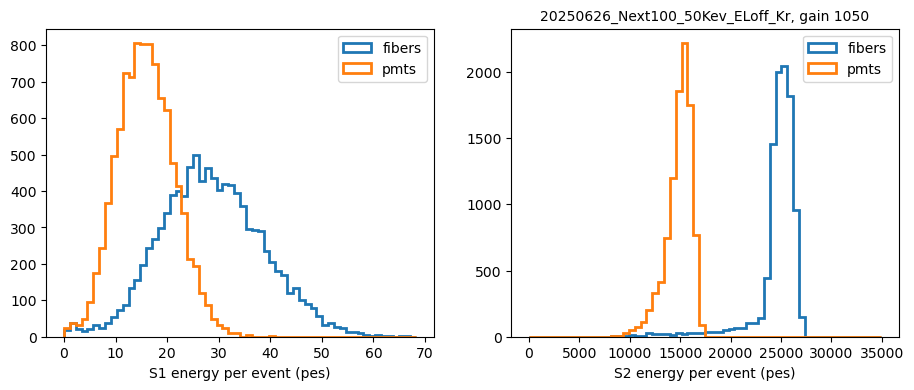

In [5]:
# Histogram ranges follow the data (S2 scales with the EL gain: ~9 000 pes at gain 365, ~25 000 at 1050 for Kr fibers)
s1_max = 1.3 * max(p["s1"]["sum"].quantile(0.99) for p in P.values())
s2_max = 1.3 * max(p["s2"]["sum"].quantile(0.99) for p in P.values())
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for det, p in P.items():
    ax[0].hist(p["s1"]["sum"], np.linspace(0, s1_max, 61), histtype="step", lw=2, label=det)
    ax[1].hist(p["s2"]["sum"], np.linspace(0, s2_max, 61), histtype="step", lw=2, label=det)
ax[0].set_xlabel("S1 energy per event (pes)"); ax[1].set_xlabel("S2 energy per event (pes)")
for a in ax: a.legend()
ax[1].set_title(f"{SAMPLE}, gain {GAIN}", fontsize=10)
r1 = P["fibers"]["s1"]["sum"].median() / P["pmts"]["s1"]["sum"].median()
r2 = P["fibers"]["s2"]["sum"].median() / P["pmts"]["s2"]["sum"].median()
print(f"median S2: fibers {P['fibers']['s2']['sum'].median():.0f} pes, PMTs {P['pmts']['s2']['sum'].median():.0f} pes")
print(f"median ratio fibers/PMTs: S1 {r1:.2f} (placeholder, see 03), S2 {r2:.2f}")

### Plots (2025 style)
Same plots as `python_cluster/notebooks/20250613_s2simulation_IChypathia.ipynb`. (The input waveforms that notebook also showed are in `03_detsim`.)

**PMAP of one event**: the peaks hypathia found in the waveforms, summed over the energy-plane sensors: S1 in magenta, S2 in black, then a zoom on each. The title gives the S1 and S2 energy of that event.
`EVENTS = [None]` takes the first event with both an S1 and an S2; put nexus event numbers in the list to choose others.

In [6]:
from icana import plots
plots.set_style()
SAVE = False         # True: also save each figure to work/figures/ (PDF for the thesis, PNG)
def show(fig, name):
    if SAVE: print("saved", plots.save(fig, name))
    plt.show()
tag = f"{SAMPLE}_{FILE}_{CHUNK}_g{GAIN}"
EVENTS = [None]

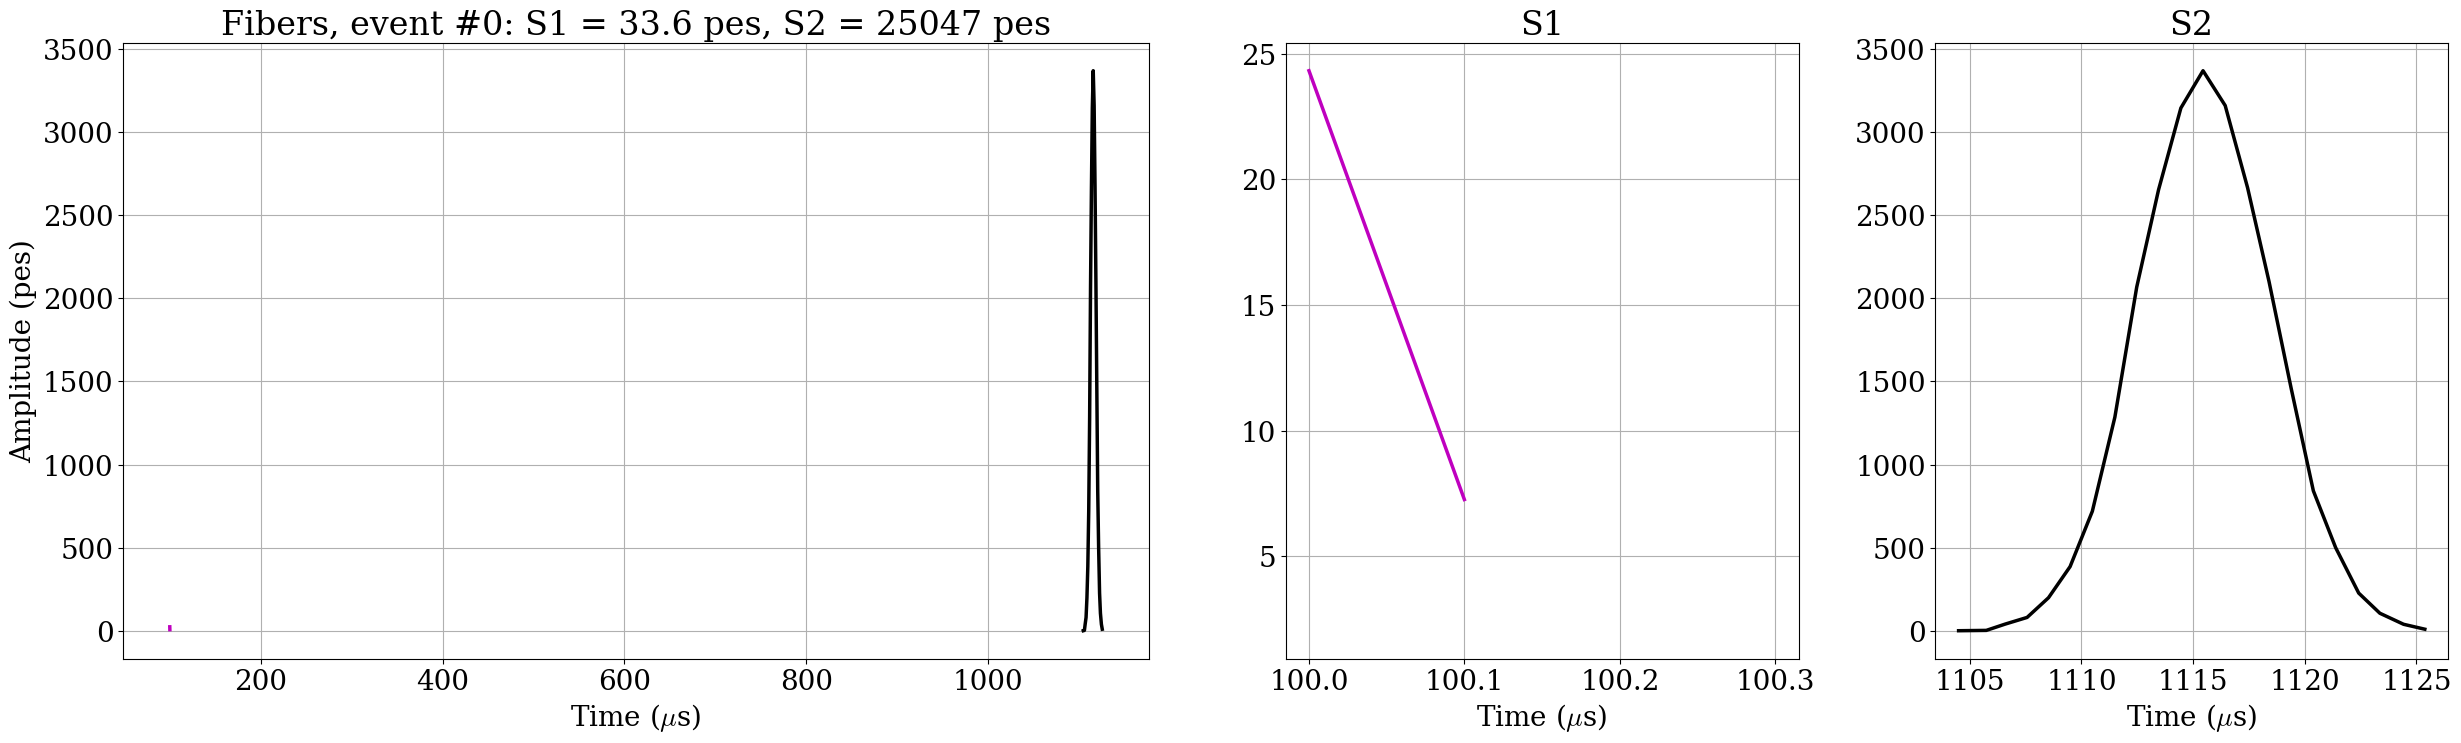

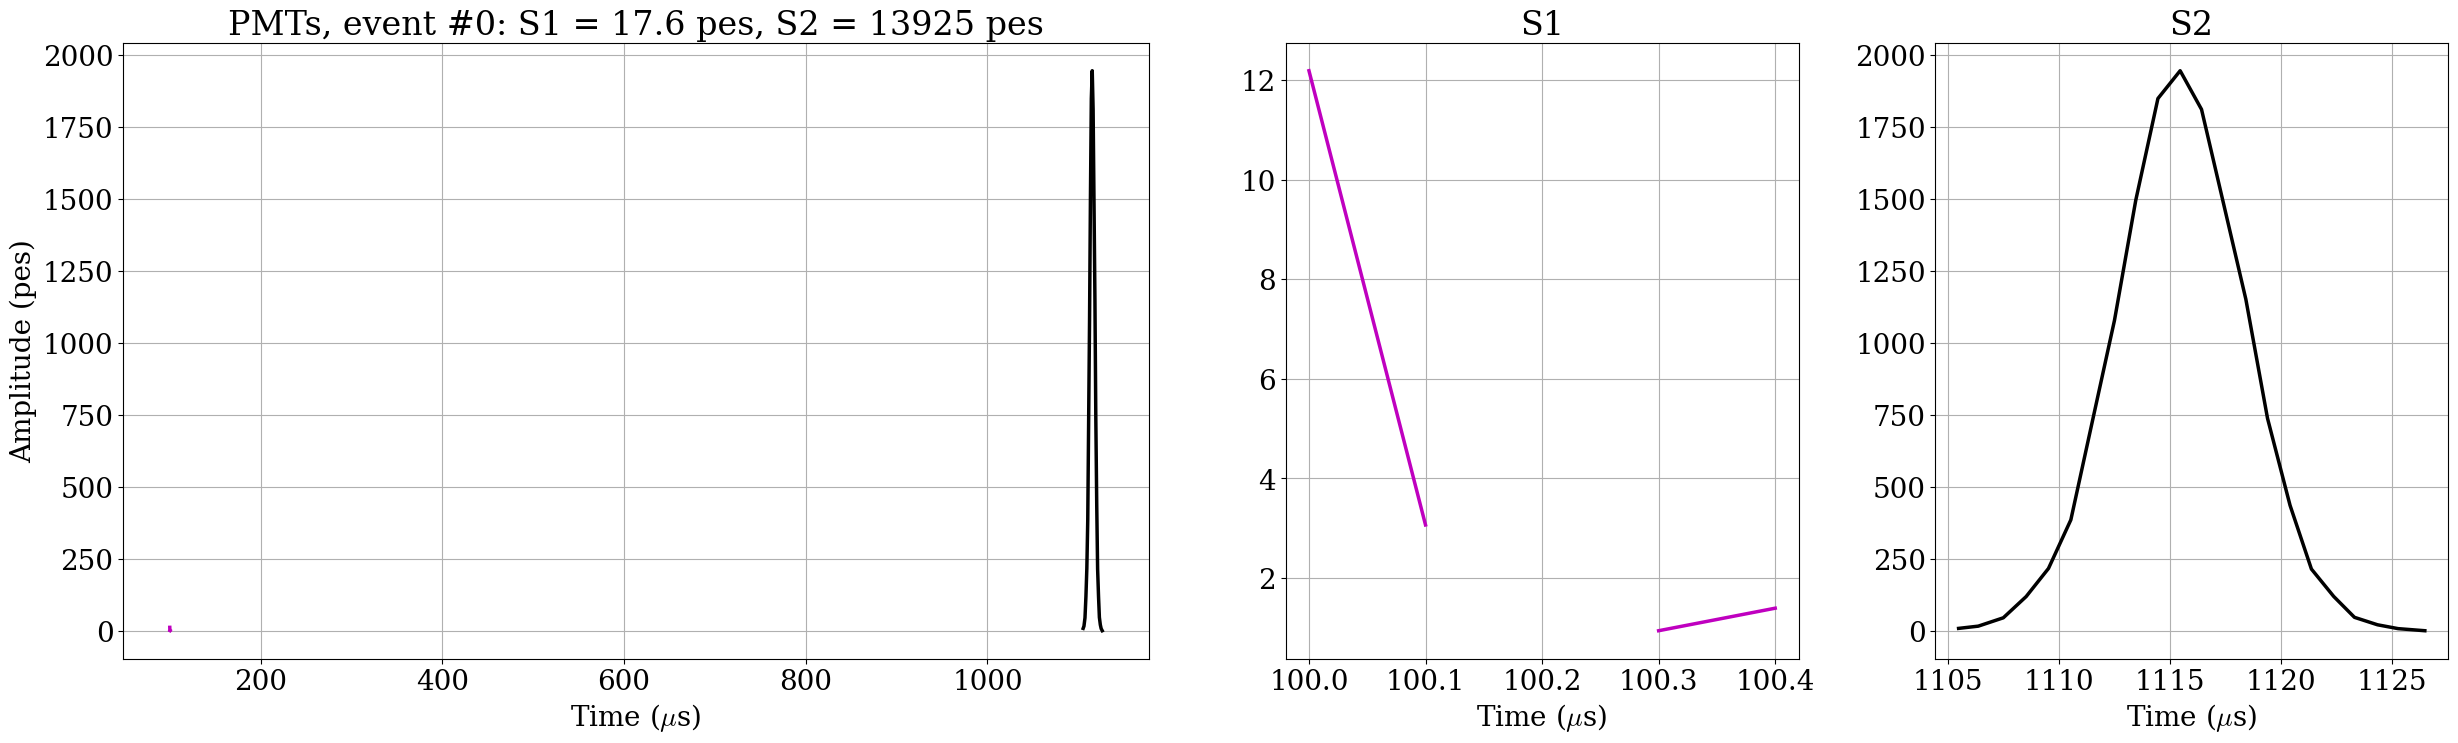

In [7]:
for det, f in [('fibers', input_file_fib), ('pmts', input_file_pmt)]:
    for ev in EVENTS:
        fig, ev = plots.pmap(f, ev)
        show(fig, f"{tag}_{det}_pmap_{ev}")